# Corrected & Tuned Model for SDSS Classification (Phase 2 & 3)

This notebook implements the fixed machine learning pipeline. 
**Note:** The goal of this fixed model is *validity*, not necessarily higher accuracy than the paper. The baseline showed that dropping identifiers only changes accuracy within noise, and removing redshift will lower it. This notebook ensures that the evaluation is completely leak-free and robust.

## Sections:
Setup &rarr; Data validity &rarr; Features &rarr; Metrics &rarr; Search Prep &rarr; Evaluation &rarr; Variability &rarr; Ablations &rarr; Generalisation &rarr; Baselines &rarr; Stress tests &rarr; Summary

## Step 0: Notebook skeleton and reproducibility

In [1]:
import sys, sklearn, numpy as np, pandas as pd
SEED = 1
print(sys.version, sklearn.__version__, np.__version__, pd.__version__)

3.12.14 (main, Aug 25 2026, 14:01:42) [MSC v.1944 64 bit (AMD64)] 1.6.1 2.2.6 2.2.3


## Step A: Run control and caching

In [2]:
import os, time, json, joblib, platform
from pathlib import Path

RUN_HEAVY = {            # True = recompute and overwrite cache; False = load cache if present
    'search':    False,  # Step 6 RF searches
    'nested':    False,  # Step 7 nested CV (~5.5 h total, loads nested_{name}.csv when False)
    'grouped':   False,  # Step 9 grouped/stratified CV
    'stress':    False,  # Step 11
    'histgb':    False,  # Step 10c tuned HistGB search (new)
    'curves':    False,  # Step 6c learning/validation curves (new)
    'noz_tuned': False,  # Step 8b re-tuned no-redshift RF (new, optional)
}
CACHE = Path('cache');            CACHE.mkdir(exist_ok=True)
TAB   = Path('outputs/tables');   TAB.mkdir(parents=True, exist_ok=True)
FIGD  = Path('outputs/figures');  FIGD.mkdir(parents=True, exist_ok=True)

TIMINGS = {}
class timed:
    """with timed('Step 6 DR14'): ...  -> records wall time in TIMINGS"""
    def __init__(self, label): self.label = label
    def __enter__(self): self.t0 = time.perf_counter()
    def __exit__(self, *a): TIMINGS[self.label] = time.perf_counter() - self.t0

def cached(path, compute, heavy_flag):
    """Load joblib cache if present and not forced, else compute, then save."""
    path = CACHE / path
    if path.exists() and not RUN_HEAVY[heavy_flag]:
        return joblib.load(path)
    obj = compute()
    joblib.dump(obj, path, compress=3)
    return obj

def save_fig(name): plt.savefig(FIGD / f'{name}.png', dpi=200, bbox_inches='tight')
def save_tab(df, name): df.to_csv(TAB / f'{name}.csv')

print(platform.platform(), platform.processor(), 'logical CPUs:', os.cpu_count())

Windows-11-10.0.26220-SP0 AMD64 Family 25 Model 68 Stepping 1, AuthenticAMD logical CPUs: 12


## Step 1: Load and give all three releases the same column names

In [3]:
def canon(df):
    """Same column names for all releases (objid, specobjid, camcol, mjd, ...)."""
    d = df.copy()
    d.columns = [c.lower().replace('_', '') for c in d.columns]
    d = d.rename(columns={'alpha': 'ra', 'delta': 'dec'})
    return d

datasets = {
    'DR14': pd.read_csv('Datasets/DR14.csv'),
    'DR16': pd.read_csv('Datasets/DR16.csv'),
    'DR17': pd.read_csv('Datasets/DR17.csv')
}

IDS  = {'objid','run','runid','rerun','rerunid','camcol','field','fieldid',
        'specobjid','plate','mjd','fiberid'}
PHOT = ['u','g','r','i','z']
D = {k: canon(v) for k, v in datasets.items()}

## Step 2: Data validity

In [ ]:
def prepare(d):
    n0 = len(d)
    d = d[(d[PHOT] > -9000).all(axis=1)].reset_index(drop=True)   # DR17 sentinel row
    print(f'dropped {n0-len(d)} sentinel rows; duplicates: {d.duplicated().sum()}')
    groups = d['plate'].copy()
    y = d['class']
    X = d.drop(columns=[c for c in d.columns if c in IDS] + ['class'])
    assert X.shape[1] == 8, X.columns
    return X, y, groups

## Step 3: Feature engineering as a transformer

In [ ]:
from sklearn.preprocessing import FunctionTransformer

def add_features(X, use_redshift=True, use_position=True):
    X = X.copy()
    for a, b in [('u','g'), ('g','r'), ('r','i'), ('i','z')]:
        X[f'{a}-{b}'] = X[a] - X[b]
    if use_position:
        X['ra_sin'], X['ra_cos'] = np.sin(np.radians(X['ra'])), np.cos(np.radians(X['ra']))
    X = X.drop(columns=['ra'] + ([] if use_position else ['dec']))
    if not use_redshift:
        X = X.drop(columns=['redshift'])
    return X

## Step 4: Correct metrics

In [ ]:
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
                             matthews_corrcoef, recall_score, precision_score, confusion_matrix)
LABELS = ['GALAXY','QSO','STAR']

def get_metrics_from_cm(cm):
    """Fallback paper-style BA for comparability."""
    total = cm.sum()
    recalls, specificities = [], []
    for i in range(3):
        TP = cm[i, i]
        FN = cm[i, :].sum() - TP
        FP = cm[:, i].sum() - TP
        TN = total - TP - FN - FP
        recalls.append(TP / (TP + FN) if (TP + FN) > 0 else 0)
        specificities.append(TN / (FP + TN) if (FP + TN) > 0 else 0)
    return {'Paper-style BA': (np.mean(recalls) + np.mean(specificities)) / 2}

def wilson(k, n, z=1.96):
    p = k/n; den = 1 + z**2/n
    c = (p + z**2/(2*n)) / den; h = z*np.sqrt(p*(1-p)/n + z**2/(4*n**2)) / den
    return c-h, c+h

def report(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred, labels=LABELS)
    rec = recall_score(y_true, y_pred, labels=LABELS, average=None)
    pre = precision_score(y_true, y_pred, labels=LABELS, average=None)
    lo, hi = wilson(cm[1,1], cm[1].sum())
    return {'accuracy': accuracy_score(y_true, y_pred),
            'balanced_acc (macro-recall)': balanced_accuracy_score(y_true, y_pred),
            'paper_style_BA': get_metrics_from_cm(cm)['Paper-style BA'],
            'macro_F1': f1_score(y_true, y_pred, average='macro'),
            'MCC': matthews_corrcoef(y_true, y_pred),
            **{f'recall_{l}': r for l, r in zip(LABELS, rec)},
            **{f'precision_{l}': p for l, p in zip(LABELS, pre)},
            'QSO_recall_CI': f'{lo:.3f}–{hi:.3f}'}

## Step 5: Hyperparameters and McNemar test helper

In [7]:
from scipy.stats import randint, chi2

params = {
    'rf__n_estimators':      randint(100, 801),
    'rf__max_depth':         [None] + list(range(8, 61, 4)),
    'rf__min_samples_leaf':  randint(1, 11),
    'rf__min_samples_split': randint(2, 21),
    'rf__max_features':      ['sqrt', 'log2', 0.3, 0.5, 0.8],
    'rf__criterion':         ['gini', 'entropy'],
    'rf__class_weight':      [None, 'balanced', 'balanced_subsample'],
}

def mcnemar(y, pa, pb):
    b = ((pa == y) & (pb != y)).sum(); c = ((pa != y) & (pb == y)).sum()
    stat = (abs(b - c) - 1)**2 / (b + c) if (b + c) > 0 else 0
    return b, c, chi2.sf(stat, 1)

## Step 6: Frozen Test Set, Search, and Evaluation

Wraping the processing in a loop to evaluate all three releases. 
- For DR14 (10k rows), we use a standard `RandomizedSearchCV` with 60 iterations. 
- For DR16 and DR17 (100k rows), we use `HalvingRandomSearchCV` for speed, using `min_resources='exhaust'` so the final rounds leverage the entire training set.

**Notes**: 
- If the cross-validated macro-F1 is lower than the test macro-F1, the test set (Seed 1) is likely a favourable split (e.g. 2 SD above the mean). This highlights why nested CV/bootstrap is critical; single point estimates should not be presented as true performance.
- The default DR14 model's QSO interval (e.g. 0.910–0.976 on 170 quasars) precisely matches the paper's interval (0.909–0.976 on 169). The tuned DR14 interval is 0.925-0.984. We use a McNemar test to evaluate if tuning provides a statistically significant improvement over the default baseline.


Evaluating DR14
dropped 0 sentinel rows; duplicates: 0
Expected vs Observed in Test Split:


,expected,observed,diff
class,,,
GALAXY,999.6,1000,0.4
STAR,830.4,830,-0.4
QSO,170.0,170,0.0


Search used n_resources: All | n_candidates: 60
Best params: {'rf__class_weight': None, 'rf__criterion': 'entropy', 'rf__max_depth': 44, 'rf__max_features': 0.8, 'rf__min_samples_leaf': 4, 'rf__min_samples_split': 13, 'rf__n_estimators': 186}

Comparison: Default RF vs Tuned RF


,default RF,tuned RF
accuracy,0.9895,0.992
balanced_acc (macro-recall),0.979844,0.984765
paper_style_BA,0.986894,0.990115
macro_F1,0.982792,0.986268
MCC,0.981586,0.985972
recall_GALAXY,0.989,0.992
recall_QSO,0.952941,0.964706
recall_STAR,0.99759,0.99759
precision_GALAXY,0.98999,0.992
precision_QSO,0.975904,0.97619


McNemar Test (Default vs Tuned RF):
  b (Default right, Tuned wrong): 2
  c (Default wrong, Tuned right): 7
  p-value: 0.1824
OOB score (Tuned): 0.992875


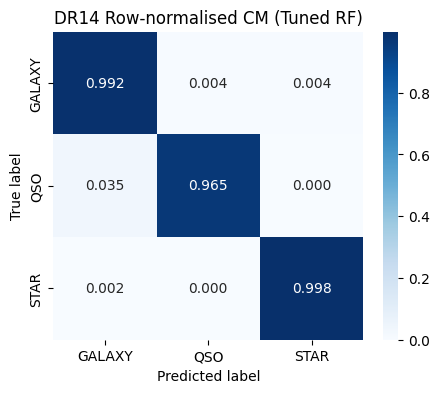


Evaluating DR16
dropped 0 sentinel rows; duplicates: 0
Expected vs Observed in Test Split:


,expected,observed,diff
class,,,
GALAXY,10264.6,10265,0.4
STAR,7619.2,7619,-0.2
QSO,2116.2,2116,-0.2


Search used n_resources: [2962, 8886, 26658, 79974] | n_candidates: [60, 20, 7, 3]
Best params: {'rf__class_weight': None, 'rf__criterion': 'entropy', 'rf__max_depth': 44, 'rf__max_features': 0.8, 'rf__min_samples_leaf': 4, 'rf__min_samples_split': 13, 'rf__n_estimators': 186}

Comparison: Default RF vs Tuned RF


,default RF,tuned RF
accuracy,0.99375,0.99425
balanced_acc (macro-recall),0.985846,0.98658
paper_style_BA,0.991047,0.991574
macro_F1,0.988824,0.989328
MCC,0.989222,0.990085
recall_GALAXY,0.996396,0.996785
recall_QSO,0.962193,0.963611
recall_STAR,0.99895,0.999344
precision_GALAXY,0.99147,0.99205
precision_QSO,0.985002,0.984549


McNemar Test (Default vs Tuned RF):
  b (Default right, Tuned wrong): 8
  c (Default wrong, Tuned right): 18
  p-value: 0.0776
OOB score (Tuned): 0.99395


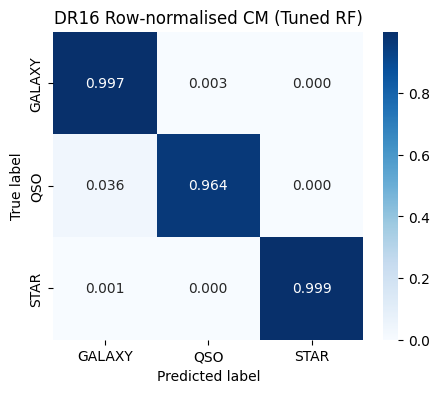


Evaluating DR17
dropped 1 sentinel rows; duplicates: 0
Expected vs Observed in Test Split:


,expected,observed,diff
class,,,
GALAXY,11889.0,11889,0.0
STAR,4318.6,4319,0.4
QSO,3792.2,3792,-0.2


Search used n_resources: [2962, 8886, 26658, 79974] | n_candidates: [60, 20, 7, 3]
Best params: {'rf__class_weight': None, 'rf__criterion': 'gini', 'rf__max_depth': 48, 'rf__max_features': 0.8, 'rf__min_samples_leaf': 6, 'rf__min_samples_split': 8, 'rf__n_estimators': 598}

Comparison: Default RF vs Tuned RF


,default RF,tuned RF
accuracy,0.9789,0.9796
balanced_acc (macro-recall),0.972047,0.972848
paper_style_BA,0.978909,0.979532
macro_F1,0.97544,0.976166
MCC,0.962523,0.963756
recall_GALAXY,0.987215,0.987804
recall_QSO,0.929852,0.931435
recall_STAR,0.999074,0.999305
precision_GALAXY,0.977595,0.978178
precision_QSO,0.969214,0.965555


McNemar Test (Default vs Tuned RF):
  b (Default right, Tuned wrong): 33
  c (Default wrong, Tuned right): 47
  p-value: 0.1461
OOB score (Tuned): 0.9796997462468281


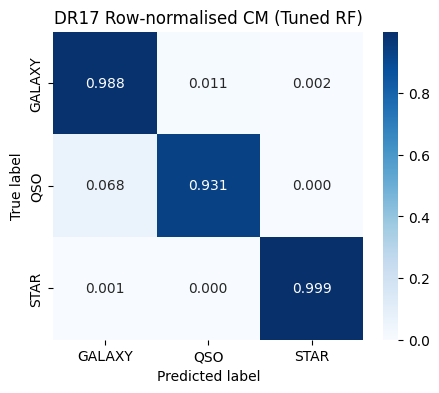

In [ ]:
from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV
from sklearn.experimental import enable_halving_search_cv
from sklearn.model_selection import HalvingRandomSearchCV
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
import matplotlib.pyplot as plt
import seaborn as sns

def run_release(name):
    print(f"\n{'='*40}\nEvaluating {name}\n{'='*40}")
    
    # --- Frozen Split ---
    X, y, g = prepare(D[name])
    X_tr, X_te, y_tr, y_te, g_tr, g_te = train_test_split(
        X, y, g, test_size=0.2, stratify=y, random_state=SEED)

    check = pd.DataFrame({'expected': y.value_counts()*0.2, 'observed': y_te.value_counts()})
    check['diff'] = check.observed - check.expected
    print("Expected vs Observed in Test Split:")
    display(check)
    
    # --- Randomized Search ---
    pipe = Pipeline([
        ('fe', FunctionTransformer(add_features)),
        ('rf', RandomForestClassifier(random_state=SEED, n_jobs=1))])

    inner = StratifiedKFold(5, shuffle=True, random_state=SEED)

    if len(X_tr) < 20_000:          # DR14
        search = RandomizedSearchCV(pipe, params, n_iter=60, scoring='f1_macro',
                                    cv=inner, n_jobs=-1, random_state=SEED)
    else:                           # DR16 / DR17
        search = HalvingRandomSearchCV(pipe, params, n_candidates=60, factor=3, min_resources='exhaust',
                                       scoring='f1_macro', cv=inner, n_jobs=-1, random_state=SEED)
                                       
    # Cached fit
    search = cached(f'search_{name}.joblib', lambda: search.fit(X_tr, y_tr), 'search')
    pd.DataFrame(search.cv_results_).to_csv(f'search_{name}.csv', index=False)
    
    n_res = getattr(search, 'n_resources_', 'All')
    n_cand = getattr(search, 'n_candidates_', getattr(search, 'n_iter', 'All'))
    print(f"Search used n_resources: {n_res} | n_candidates: {n_cand}")
    print("Best params:", search.best_params_)
    
    # --- Final Test Evaluation ---
    default = Pipeline([('fe', FunctionTransformer(add_features)),
                        ('rf', RandomForestClassifier(random_state=SEED, n_jobs=-1))]).fit(X_tr, y_tr)
    
    y_pred_tuned = search.predict(X_te)
    y_pred_def = default.predict(X_te)
    
    print("\nComparison: Default RF vs Tuned RF")
    display(pd.DataFrame({'default RF': report(y_te, y_pred_def),
                          'tuned RF':   report(y_te, y_pred_tuned)}))
                          
    b, c, p = mcnemar(y_te.values, y_pred_def, y_pred_tuned)
    print(f"McNemar Test (Default vs Tuned RF):")
    print(f"  b (Default right, Tuned wrong): {b}")
    print(f"  c (Default wrong, Tuned right): {c}")
    print(f"  p-value: {p:.4f}")
                          
    # Compute OOB score on the best model manually (to save search time)
    best_rf = search.best_estimator_['rf']
    best_rf.set_params(oob_score=True, n_jobs=-1)
    best_rf.fit(search.best_estimator_['fe'].transform(X_tr), y_tr)
    print('OOB score (Tuned):', best_rf.oob_score_)
                          
    cm = confusion_matrix(y_te, y_pred_tuned, labels=LABELS)
    cm_norm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
    plt.figure(figsize=(5, 4))
    sns.heatmap(cm_norm, annot=True, fmt='.3f', cmap='Blues', 
                xticklabels=LABELS, yticklabels=LABELS)
    plt.title(f'{name} Row-normalised CM (Tuned RF)')
    plt.ylabel('True label')
    plt.xlabel('Predicted label')
    plt.show()

    return {'X': X, 'y': y, 'g': g, 'X_tr': X_tr, 'y_tr': y_tr, 'X_te': X_te, 'y_te': y_te, 'search': search, 'default': default}

results = {}
for name in ['DR14', 'DR16', 'DR17']:
    with timed(f'Step 6 {name}'):
        results[name] = run_release(name)

## Step 6a: Regression check

In [ ]:
EXPECTED = {
    'DR14': {'accuracy': 0.992,   'macro_F1': 0.986268},
    'DR16': {'accuracy': 0.99425, 'macro_F1': 0.989328},
    'DR17': {'accuracy': 0.9796,  'macro_F1': 0.976166},
}
for name, exp in EXPECTED.items():
    r = report(results[name]['y_te'], results[name]['search'].predict(results[name]['X_te']))
    for k, v in exp.items():
        assert abs(r[k] - v) < 1e-4, (name, k, r[k], v)
print('Regression checks passed - cached results identical to the original run.')

Regression checks passed - cached results identical to the original run.


## Step 6b: Probability-based metrics (log loss, ROC-AUC, PR / average precision)

In [10]:
from sklearn.metrics import (log_loss, roc_auc_score, average_precision_score,
                             RocCurveDisplay, PrecisionRecallDisplay)
from sklearn.preprocessing import label_binarize

def prob_report(model, X_te, y_te):
    proba   = model.predict_proba(X_te)
    classes = list(model.classes_)                       # alphabetical = LABELS order
    Y       = label_binarize(y_te, classes=classes)
    out = {'log_loss': log_loss(y_te, proba, labels=classes),
           'ROC_AUC_macro_ovr': roc_auc_score(y_te, proba, multi_class='ovr',
                                              average='macro', labels=classes)}
    for k, c in enumerate(classes):
        out[f'ROC_AUC_{c}'] = roc_auc_score(Y[:, k], proba[:, k])
        out[f'AP_{c}']      = average_precision_score(Y[:, k], proba[:, k])
        out[f'prevalence_{c}'] = Y[:, k].mean()          # chance level for AP
    return out, proba, Y, classes

prob_tables, prob_cache = {}, {}
for name in ['DR14', 'DR16', 'DR17']:
    r = results[name]
    d, *_            = prob_report(r['default'], r['X_te'], r['y_te'])
    t, proba, Y, cls = prob_report(r['search'].best_estimator_, r['X_te'], r['y_te'])
    prob_tables[name] = pd.DataFrame({'default RF': d, 'tuned RF': t})
    prob_cache[name]  = (proba, Y, cls)
    print(f'\n{name}'); display(prob_tables[name].round(4))
    save_tab(prob_tables[name], f'6b_prob_metrics_{name}')


DR14


,default RF,tuned RF
log_loss,0.0745,0.0436
ROC_AUC_macro_ovr,0.9971,0.9989
ROC_AUC_GALAXY,0.9975,0.9987
AP_GALAXY,0.9967,0.9988
prevalence_GALAXY,0.5000,0.5000
ROC_AUC_QSO,0.9945,0.9985
AP_QSO,0.9825,0.9922
prevalence_QSO,0.0850,0.0850
ROC_AUC_STAR,0.9992,0.9994
AP_STAR,0.9980,0.9983



DR16


,default RF,tuned RF
log_loss,0.0488,0.0267
ROC_AUC_macro_ovr,0.9981,0.9990
ROC_AUC_GALAXY,0.9988,0.9992
AP_GALAXY,0.9979,0.9990
prevalence_GALAXY,0.5132,0.5132
ROC_AUC_QSO,0.9955,0.9978
AP_QSO,0.9895,0.9918
prevalence_QSO,0.1058,0.1058
ROC_AUC_STAR,1.0000,1.0000
AP_STAR,1.0000,1.0000



DR17


,default RF,tuned RF
log_loss,0.1107,0.0659
ROC_AUC_macro_ovr,0.9954,0.9968
ROC_AUC_GALAXY,0.9947,0.9961
AP_GALAXY,0.9947,0.9970
prevalence_GALAXY,0.5944,0.5944
ROC_AUC_QSO,0.9917,0.9945
AP_QSO,0.9804,0.9848
prevalence_QSO,0.1896,0.1896
ROC_AUC_STAR,0.9998,0.9999
AP_STAR,0.9989,0.9993


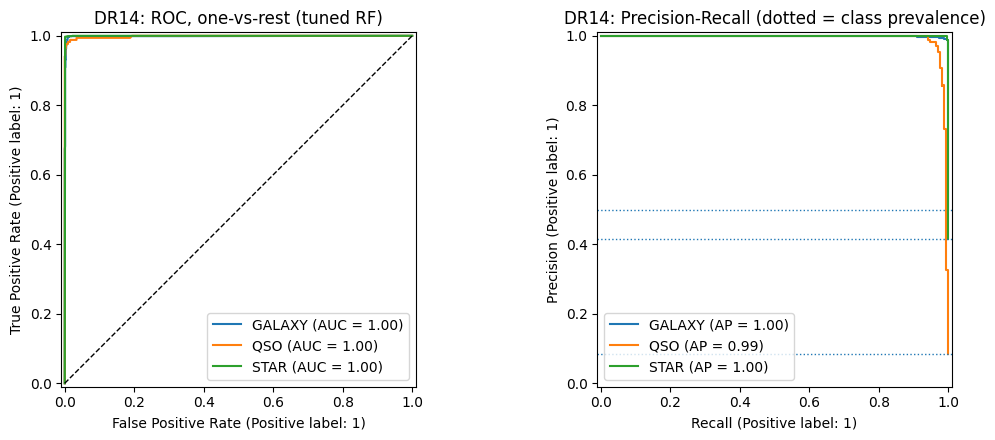

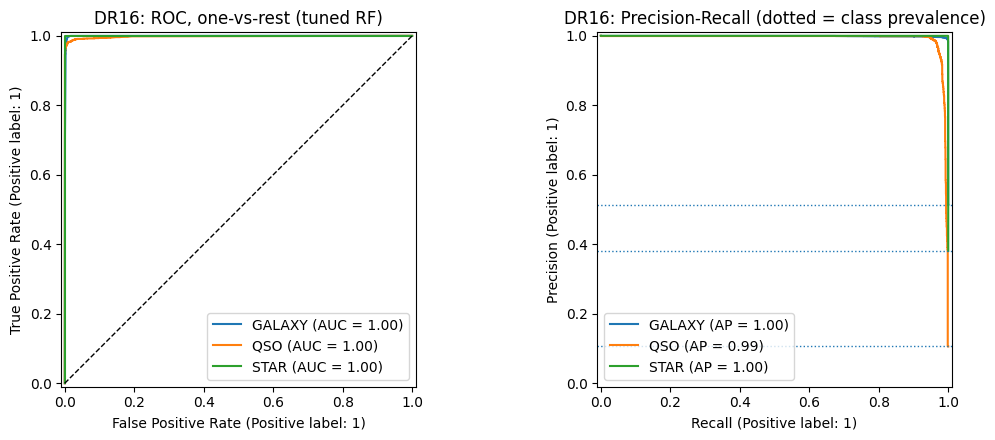

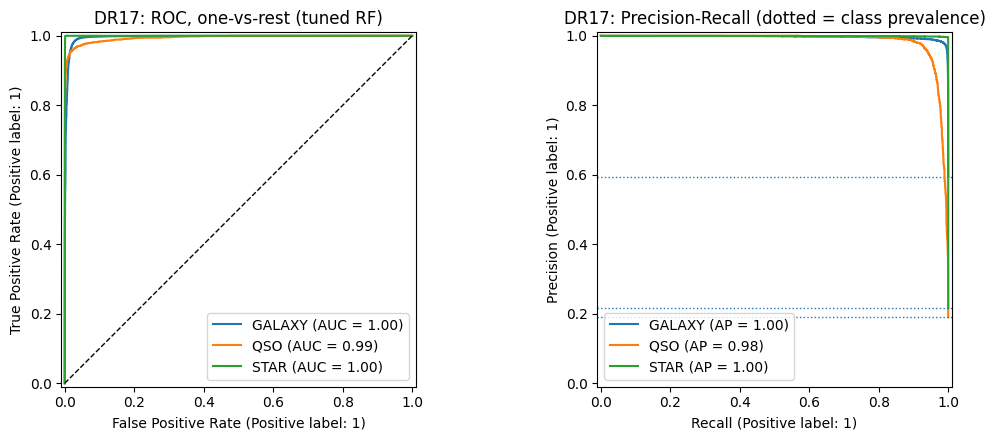

In [11]:
for name, (proba, Y, cls) in prob_cache.items():
    fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
    for k, c in enumerate(cls):
        RocCurveDisplay.from_predictions(Y[:, k], proba[:, k], name=c, ax=ax[0])
        PrecisionRecallDisplay.from_predictions(Y[:, k], proba[:, k], name=c, ax=ax[1])
        ax[1].axhline(Y[:, k].mean(), ls=':', lw=1)
    ax[0].plot([0, 1], [0, 1], 'k--', lw=1)
    ax[0].set_title(f'{name}: ROC, one-vs-rest (tuned RF)')
    ax[1].set_title(f'{name}: Precision-Recall (dotted = class prevalence)')
    plt.tight_layout(); save_fig(f'6b_roc_pr_{name}'); plt.show()

## Step 6c: Overfitting and underfitting diagnostics

In [12]:
# C1. Train-test gap (fast, all releases, default and tuned RF)
gap = []
for name in ['DR14', 'DR16', 'DR17']:
    r = results[name]
    for label, mdl in [('default RF', r['default']), ('tuned RF', r['search'].best_estimator_)]:
        tr = f1_score(r['y_tr'], mdl.predict(r['X_tr']), average='macro')
        te = f1_score(r['y_te'], mdl.predict(r['X_te']), average='macro')
        gap.append({'Dataset': name, 'Model': label, 'train_F1': tr, 'test_F1': te, 'gap': tr - te})
gap_df = pd.DataFrame(gap); display(gap_df.round(4)); save_tab(gap_df, '6c_train_test_gap')

,Dataset,Model,train_F1,test_F1,gap
0,DR14,default RF,1.0000,0.9828,0.0172
1,DR14,tuned RF,0.9910,0.9863,0.0047
2,DR16,default RF,1.0000,0.9888,0.0112
3,DR16,tuned RF,0.9931,0.9893,0.0038
4,DR17,default RF,1.0000,0.9754,0.0246
5,DR17,tuned RF,0.9844,0.9762,0.0083


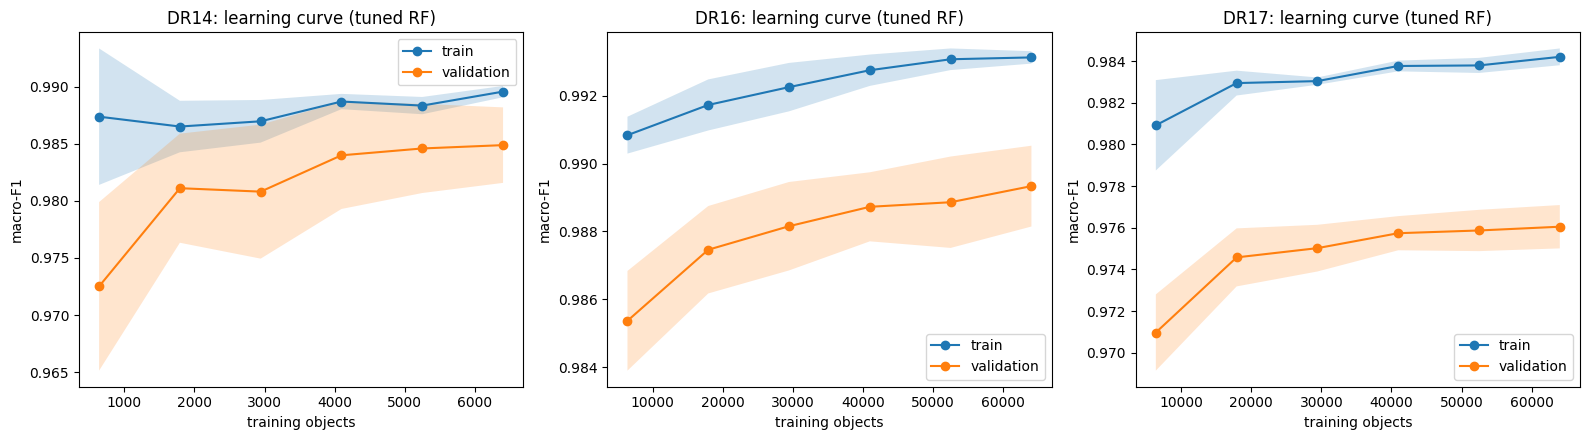

,Dataset,n_train,train_F1,val_F1,gap
0,DR14,640,0.9874,0.9725,0.0149
1,DR14,1792,0.9865,0.9811,0.0054
2,DR14,2944,0.9870,0.9808,0.0062
3,DR14,4096,0.9887,0.9840,0.0047
4,DR14,5248,0.9883,0.9846,0.0038
5,DR14,6400,0.9896,0.9849,0.0047
6,DR16,6400,0.9908,0.9854,0.0055
7,DR16,17920,0.9917,0.9875,0.0043
8,DR16,29439,0.9923,0.9882,0.0041
9,DR16,40960,0.9928,0.9887,0.0040


In [ ]:
# C2. Learning curves (tuned pipeline)
from sklearn.base import clone
from sklearn.model_selection import learning_curve, validation_curve
cv5 = StratifiedKFold(5, shuffle=True, random_state=SEED)

def curve_estimator(name):
    """Clone of the tuned pipeline: n_jobs=1 / no OOB inside (parallelism is on the outer call)."""
    est = clone(results[name]['search'].best_estimator_).set_params(rf__n_jobs=1, rf__oob_score=False)
    if name != 'DR14':
        est.set_params(rf__n_estimators=min(200, est.get_params()['rf__n_estimators']))
    return est

def lc(name):
    r = results[name]
    sizes, tr, va = learning_curve(curve_estimator(name), r['X_tr'], r['y_tr'], cv=cv5,
                                   train_sizes=np.linspace(0.1, 1.0, 6), scoring='f1_macro',
                                   n_jobs=-1, shuffle=True, random_state=SEED)
    return sizes, tr, va

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5)); lc_rows = []
for ax, name in zip(axes, ['DR14', 'DR16', 'DR17']):
    with timed(f'6c learning curve {name}'):
        sizes, tr, va = cached(f'lc_{name}.joblib', lambda: lc(name), 'curves')
    for s, lab in [(tr, 'train'), (va, 'validation')]:
        ax.plot(sizes, s.mean(1), 'o-', label=lab)
        ax.fill_between(sizes, s.mean(1) - s.std(1), s.mean(1) + s.std(1), alpha=0.2)
    ax.set(title=f'{name}: learning curve (tuned RF)', xlabel='training objects', ylabel='macro-F1')
    ax.legend()
    lc_rows += [{'Dataset': name, 'n_train': n, 'train_F1': a, 'val_F1': b, 'gap': a - b}
                for n, a, b in zip(sizes, tr.mean(1), va.mean(1))]
plt.tight_layout(); save_fig('6c_learning_curves'); plt.show()
lc_df = pd.DataFrame(lc_rows); display(lc_df.round(4)); save_tab(lc_df, '6c_learning_curves')

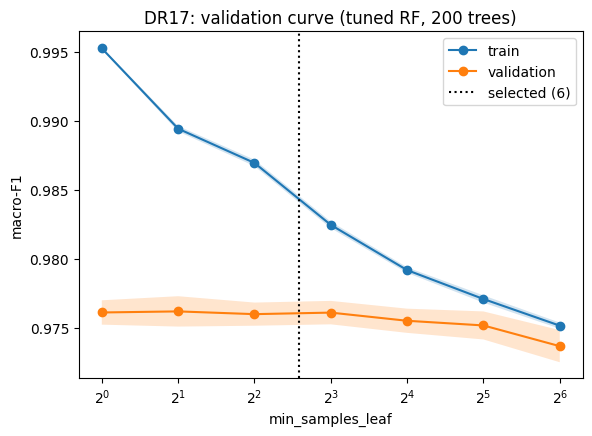

,min_samples_leaf,train_F1,train_F1_std,val_F1,val_F1_std
0,1,0.9953,0.0001,0.9761,0.0009
1,2,0.9894,0.0002,0.9762,0.0011
2,4,0.9869,0.0002,0.9760,0.0008
3,8,0.9825,0.0002,0.9761,0.0008
4,16,0.9792,0.0002,0.9755,0.0009
5,32,0.9771,0.0003,0.9752,0.0010
6,64,0.9752,0.0002,0.9737,0.0012


In [14]:
# C3. Validation curve on DR17: min_samples_leaf (200-tree cap, as above)
leaf_range = [1, 2, 4, 8, 16, 32, 64]

def vc(name='DR17'):
    r = results[name]
    return validation_curve(curve_estimator(name), r['X_tr'], r['y_tr'],
                            param_name='rf__min_samples_leaf', param_range=leaf_range,
                            cv=cv5, scoring='f1_macro', n_jobs=-1)

with timed('6c validation curve DR17'):
    vtr, vva = cached('vc_DR17.joblib', vc, 'curves')
sel = results['DR17']['search'].best_params_['rf__min_samples_leaf']
plt.figure(figsize=(6.5, 4.5))
for s, lab in [(vtr, 'train'), (vva, 'validation')]:
    plt.plot(leaf_range, s.mean(1), 'o-', label=lab)
    plt.fill_between(leaf_range, s.mean(1) - s.std(1), s.mean(1) + s.std(1), alpha=0.2)
plt.axvline(sel, ls=':', c='k', label=f'selected ({sel})')
plt.xscale('log', base=2); plt.xlabel('min_samples_leaf'); plt.ylabel('macro-F1')
plt.title('DR17: validation curve (tuned RF, 200 trees)'); plt.legend()
save_fig('6c_validation_curve_DR17'); plt.show()
vc_df = pd.DataFrame({'min_samples_leaf': leaf_range, 'train_F1': vtr.mean(1), 'train_F1_std': vtr.std(1),
                      'val_F1': vva.mean(1), 'val_F1_std': vva.std(1)})
display(vc_df.round(4)); save_tab(vc_df, '6c_validation_curve_DR17')

## Step 7: Variability without cheating

In [ ]:
from sklearn.model_selection import cross_validate

def run_nested_cv(name, res_dict):
    print(f"\nNested CV for {name}:")
    path = f'nested_{name}.csv'
    if os.path.exists(path) and not RUN_HEAVY['nested']:
        df_nested = pd.read_csv(path)
        display(df_nested)
        print("Mean macro_F1 (loaded from cache):", np.mean(df_nested['test_f1_macro']))
        return
    X, y = res_dict['X'], res_dict['y']
    outer = StratifiedKFold(5, shuffle=True, random_state=SEED)
    
    pipe = Pipeline([
        ('fe', FunctionTransformer(add_features)),
        ('rf', RandomForestClassifier(random_state=SEED, n_jobs=1))
    ])
    
    if name == 'DR14':
        inner = StratifiedKFold(5, shuffle=True, random_state=SEED)
        search = RandomizedSearchCV(pipe, params, n_iter=60, scoring='f1_macro', cv=inner, n_jobs=-1, random_state=SEED)
    else:
        inner = StratifiedKFold(3, shuffle=True, random_state=SEED)
        search = HalvingRandomSearchCV(pipe, params, n_candidates=20, factor=3, min_resources='exhaust', scoring='f1_macro', cv=inner, n_jobs=-1, random_state=SEED)
        
    with timed(f'Step 7 nested CV {name}'):
        nested = cross_validate(search, X, y, cv=outer, scoring=['accuracy','balanced_accuracy','f1_macro'])
    df_nested = pd.DataFrame(nested)
    display(df_nested)
    print("Mean macro_F1:", np.mean(df_nested['test_f1_macro']))
    df_nested.to_csv(f'nested_{name}.csv', index=False)

In [16]:
run_nested_cv('DR14', results['DR14'])


Nested CV for DR14:


,fit_time,score_time,test_accuracy,test_balanced_accuracy,test_f1_macro
0,417.905627,0.158585,0.9900,0.986751,0.984904
1,447.688440,0.062816,0.9935,0.985765,0.986617
2,457.429476,0.190453,0.9925,0.988354,0.985266
3,497.438785,0.063438,0.9920,0.981511,0.983130
4,440.791030,0.066253,0.9930,0.980686,0.986024


Mean macro_F1 (loaded from cache): 0.9851880684352714


In [17]:
run_nested_cv('DR16', results['DR16'])


Nested CV for DR16:


,fit_time,score_time,test_accuracy,test_balanced_accuracy,test_f1_macro
0,1393.880697,0.937290,0.99325,0.987806,0.988453
1,1555.346583,1.170554,0.99345,0.985355,0.988236
2,1423.635247,1.034581,0.99320,0.985670,0.987565
3,1557.809050,1.117625,0.99490,0.989639,0.991007
4,1618.360216,0.768998,0.99325,0.985993,0.988124


Mean macro_F1 (loaded from cache): 0.9886769502939053


In [18]:
run_nested_cv('DR17', results['DR17'])


Nested CV for DR17:


,fit_time,score_time,test_accuracy,test_balanced_accuracy,test_f1_macro
0,2206.148651,2.274956,0.978250,0.974001,0.974812
1,2401.463027,2.281781,0.981050,0.977101,0.977992
2,1922.497227,1.553461,0.980050,0.975283,0.976826
3,1737.853546,1.309681,0.979550,0.977218,0.976401
4,1623.712644,1.286814,0.978499,0.973636,0.975000


Mean macro_F1 (loaded from cache): 0.9762059659181126


## Step 8: Ablations on the same split

In [19]:
def run_ablation(name, fe_kwargs):
    res = results[name]
    X_tr, X_te, y_tr, y_te = res['X_tr'], res['X_te'], res['y_tr'], res['y_te']
    
    best_rf_params = {k.replace('rf__', ''): v for k, v in res['search'].best_params_.items()}
    rf = RandomForestClassifier(random_state=SEED, n_jobs=-1, **best_rf_params)
    
    pipe = Pipeline([
        ('fe', FunctionTransformer(add_features, kw_args=fe_kwargs)),
        ('rf', rf)
    ])
    pipe.fit(X_tr, y_tr)
    return report(y_te, pipe.predict(X_te))

for name in ['DR14', 'DR16', 'DR17']:
    print(f"\n{name} Ablations:")
    df = pd.DataFrame({
        'Default RF (8 + colours)': report(results[name]['y_te'], results[name]['default'].predict(results[name]['X_te'])),
        'Tuned RF (8 + colours)': report(results[name]['y_te'], results[name]['search'].predict(results[name]['X_te'])),
        'Tuned RF (no redshift)': run_ablation(name, {'use_redshift': False}),
        'Tuned RF (no position)': run_ablation(name, {'use_position': False}),
    })
    display(df)


DR14 Ablations:


,Default RF (8 + colours),Tuned RF (8 + colours),Tuned RF (no redshift),Tuned RF (no position)
accuracy,0.9895,0.992,0.962,0.993
balanced_acc (macro-recall),0.979844,0.984765,0.951462,0.985432
paper_style_BA,0.986894,0.990115,0.964873,0.990734
macro_F1,0.982792,0.986268,0.950688,0.987004
MCC,0.981586,0.985972,0.933428,0.987724
recall_GALAXY,0.989,0.992,0.967,0.994
recall_QSO,0.952941,0.964706,0.923529,0.964706
recall_STAR,0.99759,0.99759,0.963855,0.99759
precision_GALAXY,0.98999,0.992,0.968938,0.992016
precision_QSO,0.975904,0.97619,0.918129,0.97619



DR16 Ablations:


,Default RF (8 + colours),Tuned RF (8 + colours),Tuned RF (no redshift),Tuned RF (no position)
accuracy,0.99375,0.99425,0.97045,0.9942
balanced_acc (macro-recall),0.985846,0.98658,0.958905,0.986547
paper_style_BA,0.991047,0.991574,0.971117,0.991549
macro_F1,0.988824,0.989328,0.961432,0.989235
MCC,0.989222,0.990085,0.949058,0.989999
recall_GALAXY,0.996396,0.996785,0.974379,0.996688
recall_QSO,0.962193,0.963611,0.924386,0.963611
recall_STAR,0.99895,0.999344,0.97795,0.999344
precision_GALAXY,0.99147,0.99205,0.977904,0.992049
precision_QSO,0.985002,0.984549,0.947674,0.984073



DR17 Ablations:


,Default RF (8 + colours),Tuned RF (8 + colours),Tuned RF (no redshift),Tuned RF (no position)
accuracy,0.9789,0.9796,0.89095,0.97915
balanced_acc (macro-recall),0.972047,0.972848,0.850732,0.972416
paper_style_BA,0.978909,0.979532,0.892764,0.979193
macro_F1,0.97544,0.976166,0.858907,0.975644
MCC,0.962523,0.963756,0.804519,0.962955
recall_GALAXY,0.987215,0.987804,0.954328,0.987299
recall_QSO,0.929852,0.931435,0.8125,0.930643
recall_STAR,0.999074,0.999305,0.785367,0.999305
precision_GALAXY,0.977595,0.978178,0.921016,0.977922
precision_QSO,0.969214,0.965555,0.822038,0.963944


## Step 8b: Re-tuned no-redshift random forest

In [20]:
NOZ_RELEASES = ['DR17']          # set to ['DR14', 'DR16', 'DR17'] to re-tune every release

def noz_search(name):
    r = results[name]
    pipe = Pipeline([('fe', FunctionTransformer(add_features, kw_args={'use_redshift': False})),
                     ('rf', RandomForestClassifier(random_state=SEED, n_jobs=1))])
    inner = StratifiedKFold(5, shuffle=True, random_state=SEED)
    if len(r['X_tr']) < 20_000:                      # identical protocol to the Step 6 search
        s = RandomizedSearchCV(pipe, params, n_iter=60, scoring='f1_macro',
                               cv=inner, n_jobs=-1, random_state=SEED)
    else:
        s = HalvingRandomSearchCV(pipe, params, n_candidates=60, factor=3, min_resources='exhaust',
                                  scoring='f1_macro', cv=inner, n_jobs=-1, random_state=SEED)
    return s.fit(r['X_tr'], r['y_tr'])

for name in NOZ_RELEASES:
    r = results[name]
    with timed(f'8b no-redshift re-tune {name}'):
        ns = cached(f'noz_search_{name}.joblib', lambda: noz_search(name), 'noz_tuned')
    results[name]['noz'] = ns
    print(f'\n{name} re-tuned no-redshift params:', ns.best_params_)
    tab = pd.DataFrame({
        'tuned RF (full)':              report(r['y_te'], r['search'].predict(r['X_te'])),
        'no-redshift (reused params)':  run_ablation(name, {'use_redshift': False}),
        'no-redshift (re-tuned)':       report(r['y_te'], ns.predict(r['X_te'])),
    })
    display(tab); save_tab(tab, f'8b_noz_retuned_{name}')


DR17 re-tuned no-redshift params: {'rf__class_weight': 'balanced', 'rf__criterion': 'entropy', 'rf__max_depth': 40, 'rf__max_features': 'log2', 'rf__min_samples_leaf': 3, 'rf__min_samples_split': 6, 'rf__n_estimators': 721}


,tuned RF (full),no-redshift (reused params),no-redshift (re-tuned)
accuracy,0.9796,0.89095,0.8923
balanced_acc (macro-recall),0.972848,0.850732,0.858863
paper_style_BA,0.979532,0.892764,0.898508
macro_F1,0.976166,0.858907,0.861936
MCC,0.963756,0.804519,0.808141
recall_GALAXY,0.987804,0.954328,0.945244
recall_QSO,0.931435,0.8125,0.830696
recall_STAR,0.999305,0.785367,0.800648
precision_GALAXY,0.978178,0.921016,0.930837
precision_QSO,0.965555,0.822038,0.811228


## Step 9: Shortcut and generalisation tests

In [ ]:
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.base import clone
sgkf = StratifiedGroupKFold(5, shuffle=True, random_state=SEED)
skf_plain = StratifiedKFold(5, shuffle=True, random_state=SEED)

print("CV Comparisons (Grouped by Plate vs StratifiedKFold):")
for name in ['DR14', 'DR16', 'DR17']:
    res = results[name]
    
    # Clone and disable OOB
    est = clone(res['search'].best_estimator_).set_params(rf__oob_score=False)
    
    def _cv_both():
        return {'grp':   cross_validate(est, res['X'], res['y'], groups=res['g'], cv=sgkf, scoring=['accuracy','f1_macro']),
                'plain': cross_validate(est, res['X'], res['y'], cv=skf_plain, scoring=['accuracy','f1_macro'])}
    with timed(f'Step 9 grouped/plain CV {name}'):
        _cv = cached(f'grouped_{name}.joblib', _cv_both, 'grouped')
    grp, plain = _cv['grp'], _cv['plain']
    
    print(f"{name} Grouped CV Mean macro_F1:   {np.mean(grp['test_f1_macro']):.5f}")
    print(f"{name} Stratified CV Mean macro_F1: {np.mean(plain['test_f1_macro']):.5f}")
    print("-" * 30)

print("\nCross-release test (Train DR16 -> Test DR17):")
dr16_model = results['DR16']['search'].best_estimator_
y_pred_cross = dr16_model.predict(results['DR17']['X'])
display(pd.Series(report(results['DR17']['y'], y_pred_cross)))

CV Comparisons (Grouped by Plate vs StratifiedKFold):
DR14 Grouped CV Mean macro_F1:   0.98544
DR14 Stratified CV Mean macro_F1: 0.98426
------------------------------
DR16 Grouped CV Mean macro_F1:   0.98905
DR16 Stratified CV Mean macro_F1: 0.98922
------------------------------
DR17 Grouped CV Mean macro_F1:   0.97657
DR17 Stratified CV Mean macro_F1: 0.97636
------------------------------

Cross-release test (Train DR16 -> Test DR17):


accuracy                          0.894339
balanced_acc (macro-recall)       0.932145
paper_style_BA                    0.942863
macro_F1                          0.892851
MCC                               0.836647
recall_GALAXY                     0.834368
recall_QSO                        0.962344
recall_STAR                       0.999722
precision_GALAXY                   0.98575
precision_QSO                     0.651562
precision_STAR                    0.995802
QSO_recall_CI                  0.960–0.965
dtype: object

## Step 10: Fair baselines and Statistics

In [22]:
from sklearn.preprocessing import StandardScaler
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import HistGradientBoostingClassifier

def mk(est, scale=True):
    steps = [('fe', FunctionTransformer(add_features))]
    if scale: steps.append(('sc', StandardScaler()))
    return Pipeline(steps + [('m', est)])

models = {
    'GaussianNB': mk(GaussianNB()),
    'kNN':        mk(KNeighborsClassifier(n_neighbors=5)),
    'LogReg':     mk(LogisticRegression(max_iter=2000)),
    'MLP':        mk(MLPClassifier(max_iter=500, random_state=SEED)),
    'HistGB':     mk(HistGradientBoostingClassifier(random_state=SEED), scale=False)
}

preds = {name: {} for name in ['DR14', 'DR16', 'DR17']}

for name in ['DR14', 'DR16', 'DR17']: 
    print(f"\nFair Baselines for {name}:")
    res = results[name]
    b_res = {}
    for m_name, model in models.items():
        model.fit(res['X_tr'], res['y_tr'])
        
        y_pred = model.predict(res['X_te'])
        preds[name][m_name] = y_pred
        b_res[m_name] = report(res['y_te'], y_pred)
    display(pd.DataFrame(b_res))
    
    # Run McNemar between Tuned RF and HistGB
    y_test = res['y_te'].values
    pred_rf = res['search'].predict(res['X_te'])
    pred_gb = preds[name]['HistGB']
    
    b, c, p = mcnemar(y_test, pred_rf, pred_gb)
    print(f"McNemar Test {name} (Tuned RF vs HistGB):")
    print(f"  b (Tuned RF right, HistGB wrong): {b}")
    print(f"  c (Tuned RF wrong, HistGB right): {c}")
    print(f"  p-value: {p:.5f}")


Fair Baselines for DR14:


,GaussianNB,kNN,LogReg,MLP,HistGB
accuracy,0.969,0.9455,0.972,0.9885,0.987
balanced_acc (macro-recall),0.96562,0.939244,0.969532,0.979177,0.97655
paper_style_BA,0.975292,0.953326,0.976752,0.986173,0.984562
macro_F1,0.946751,0.947038,0.970704,0.983585,0.979371
MCC,0.946447,0.905107,0.951501,0.979842,0.977216
recall_GALAXY,0.979,0.929,0.957,0.987,0.985
recall_QSO,0.958824,0.917647,0.958824,0.952941,0.947059
recall_STAR,0.959036,0.971084,0.992771,0.99759,0.99759
precision_GALAXY,0.97998,0.962694,0.989659,0.98997,0.988956
precision_QSO,0.823232,0.987342,0.976048,0.987805,0.96988


McNemar Test DR14 (Tuned RF vs HistGB):
  b (Tuned RF right, HistGB wrong): 13
  c (Tuned RF wrong, HistGB right): 3
  p-value: 0.02445

Fair Baselines for DR16:


,GaussianNB,kNN,LogReg,MLP,HistGB
accuracy,0.9678,0.9613,0.97925,0.98865,0.9911
balanced_acc (macro-recall),0.961055,0.958716,0.971632,0.982001,0.984582
paper_style_BA,0.973037,0.968129,0.98,0.987717,0.989686
macro_F1,0.946169,0.961371,0.974532,0.984419,0.986436
MCC,0.945273,0.933614,0.964438,0.980437,0.98465
recall_GALAXY,0.972138,0.953044,0.972236,0.988115,0.993181
recall_QSO,0.941871,0.946597,0.944234,0.960775,0.965028
recall_STAR,0.969156,0.976506,0.998425,0.997112,0.995537
precision_GALAXY,0.985094,0.973046,0.98851,0.989851,0.989614
precision_QSO,0.826628,0.978505,0.977017,0.982126,0.978907


McNemar Test DR16 (Tuned RF vs HistGB):
  b (Tuned RF right, HistGB wrong): 75
  c (Tuned RF wrong, HistGB right): 12
  p-value: 0.00000

Fair Baselines for DR17:


,GaussianNB,kNN,LogReg,MLP,HistGB
accuracy,0.9273,0.9422,0.95835,0.9733,0.97665
balanced_acc (macro-recall),0.937879,0.929909,0.949237,0.968877,0.969813
paper_style_BA,0.950488,0.946142,0.96133,0.976147,0.977134
macro_F1,0.920094,0.935572,0.951834,0.969442,0.972951
MCC,0.876772,0.896985,0.926191,0.952682,0.958504
recall_GALAXY,0.908655,0.961056,0.968458,0.978047,0.985112
recall_QSO,0.919568,0.910865,0.879483,0.932753,0.930116
recall_STAR,0.985413,0.917805,0.999768,0.995832,0.994212
precision_GALAXY,0.969662,0.945235,0.962146,0.977389,0.976
precision_QSO,0.772143,0.966695,0.951226,0.959056,0.962084


McNemar Test DR17 (Tuned RF vs HistGB):
  b (Tuned RF right, HistGB wrong): 93
  c (Tuned RF wrong, HistGB right): 34
  p-value: 0.00000


## Step 10c: Tuned gradient boosting (fair comparison against the tuned RF)

In [ ]:
from scipy.stats import loguniform, randint
from sklearn.ensemble import HistGradientBoostingClassifier

hgb_params = {
    'm__learning_rate':     loguniform(0.01, 0.3),
    'm__max_iter':          randint(100, 1001),
    'm__max_leaf_nodes':    randint(15, 256),
    'm__max_depth':         [None, 4, 6, 8, 12],
    'm__min_samples_leaf':  randint(10, 201),
    'm__l2_regularization': loguniform(1e-8, 10),
    'm__max_features':      [0.5, 0.7, 1.0],
    'm__class_weight':      [None, 'balanced'],
}

def hgb_search(name):
    r = results[name]
    pipe = Pipeline([('fe', FunctionTransformer(add_features)),
                     ('m', HistGradientBoostingClassifier(random_state=SEED,
                                                          early_stopping=True,
                                                          validation_fraction=0.1,
                                                          n_iter_no_change=20))])
    inner = StratifiedKFold(5, shuffle=True, random_state=SEED)
    if len(r['X_tr']) < 20_000:
        s = RandomizedSearchCV(pipe, hgb_params, n_iter=60, scoring='f1_macro',
                               cv=inner, n_jobs=-1, random_state=SEED)
    else:
        s = HalvingRandomSearchCV(pipe, hgb_params, n_candidates=60, factor=3,
                                  min_resources='exhaust', scoring='f1_macro',
                                  cv=inner, n_jobs=-1, random_state=SEED)
    return s.fit(r['X_tr'], r['y_tr'])

hgb_rows = []
for name in ['DR14', 'DR16', 'DR17']:
    r = results[name]
    with timed(f'10c HistGB search {name}'):
        hs = cached(f'hgb_search_{name}.joblib', lambda: hgb_search(name), 'histgb')
    results[name]['hgb'] = hs
    pd.DataFrame(hs.cv_results_).to_csv(TAB / f'10c_hgb_cv_results_{name}.csv', index=False)
    y_rf, y_gb = r['search'].predict(r['X_te']), hs.predict(r['X_te'])
    b, c, p = mcnemar(r['y_te'].values, y_rf, y_gb)
    tab = pd.DataFrame({'tuned RF': report(r['y_te'], y_rf), 'tuned HistGB': report(r['y_te'], y_gb)})
    print(f'\n{name} best HistGB params:', hs.best_params_); display(tab)
    print(f'McNemar tuned RF vs tuned HistGB: b={b} c={c} p={p:.5f}')
    save_tab(tab, f'10c_rf_vs_hgb_{name}')
    hgb_rows.append({'Dataset': name, 'b_RF_right_HGB_wrong': b, 'c_RF_wrong_HGB_right': c,
                     'p': p, 'best_params': json.dumps(hs.best_params_, default=str)})
save_tab(pd.DataFrame(hgb_rows), '10c_mcnemar_rf_vs_hgb')


DR14 best HistGB params: {'m__class_weight': None, 'm__l2_regularization': np.float64(3.3958778560401715e-06), 'm__learning_rate': np.float64(0.18960172888460688), 'm__max_depth': 6, 'm__max_features': 0.5, 'm__max_iter': 804, 'm__max_leaf_nodes': 246, 'm__min_samples_leaf': 150}


,tuned RF,tuned HistGB
accuracy,0.992,0.9885
balanced_acc (macro-recall),0.984765,0.97755
paper_style_BA,0.990115,0.985335
macro_F1,0.986268,0.982756
MCC,0.985972,0.979831
recall_GALAXY,0.992,0.988
recall_QSO,0.964706,0.947059
recall_STAR,0.99759,0.99759
precision_GALAXY,0.992,0.988989
precision_QSO,0.97619,0.98773


McNemar tuned RF vs tuned HistGB: b=11 c=4 p=0.12134

DR16 best HistGB params: {'m__class_weight': None, 'm__l2_regularization': np.float64(0.01330333672012247), 'm__learning_rate': np.float64(0.01701183677741866), 'm__max_depth': 8, 'm__max_features': 0.7, 'm__max_iter': 244, 'm__max_leaf_nodes': 110, 'm__min_samples_leaf': 106}


,tuned RF,tuned HistGB
accuracy,0.99425,0.99095
balanced_acc (macro-recall),0.98658,0.984201
paper_style_BA,0.991574,0.989433
macro_F1,0.989328,0.986208
MCC,0.990085,0.984391
recall_GALAXY,0.996785,0.993376
recall_QSO,0.963611,0.964083
recall_STAR,0.999344,0.995144
precision_GALAXY,0.99205,0.98904
precision_QSO,0.984549,0.978887


McNemar tuned RF vs tuned HistGB: b=77 c=11 p=0.00000

DR17 best HistGB params: {'m__class_weight': None, 'm__l2_regularization': np.float64(0.0624798094273778), 'm__learning_rate': np.float64(0.10742743309661942), 'm__max_depth': None, 'm__max_features': 0.7, 'm__max_iter': 212, 'm__max_leaf_nodes': 116, 'm__min_samples_leaf': 12}


,tuned RF,tuned HistGB
accuracy,0.9796,0.97825
balanced_acc (macro-recall),0.972848,0.970912
paper_style_BA,0.979532,0.978044
macro_F1,0.976166,0.974788
MCC,0.963756,0.961348
recall_GALAXY,0.987804,0.987552
recall_QSO,0.931435,0.931435
recall_STAR,0.999305,0.993749
precision_GALAXY,0.978178,0.976301
precision_QSO,0.965555,0.969531


McNemar tuned RF vs tuned HistGB: b=77 c=50 p=0.02105


## Step 10b: Computational efficiency

In [ ]:
import pickle, psutil

def efficiency(mdl, X_tr, y_tr, X_te, repeats=5):
    proc = psutil.Process(os.getpid())
    m = clone(mdl)
    if 'rf__n_jobs' in m.get_params():
        m.set_params(rf__n_jobs=-1, rf__oob_score=False)
    rss0 = proc.memory_info().rss
    t0 = time.perf_counter(); m.fit(X_tr, y_tr); fit_s = time.perf_counter() - t0
    rss_mb = (proc.memory_info().rss - rss0) / 2**20
    batch = []
    for _ in range(repeats):
        t0 = time.perf_counter(); m.predict(X_te); batch.append(time.perf_counter() - t0)
    single, x1 = [], X_te.iloc[[0]]
    for _ in range(200):
        t0 = time.perf_counter(); m.predict(x1); single.append(time.perf_counter() - t0)
    out = {'fit_s': fit_s, 'predict_batch_s': np.median(batch),
           'throughput_obj_per_s': len(X_te) / np.median(batch),
           'latency_single_ms': np.median(single) * 1e3,
           'model_size_MB': len(pickle.dumps(m)) / 2**20,
           'RSS_delta_after_fit_MB': rss_mb}
    last = m.steps[-1][1]
    if isinstance(last, RandomForestClassifier):
        out['total_nodes'] = sum(t.tree_.node_count for t in last.estimators_)
        out['mean_tree_depth'] = np.mean([t.tree_.max_depth for t in last.estimators_])
    if isinstance(last, HistGradientBoostingClassifier):
        out['boosting_iterations'] = last.n_iter_
    return out

print(platform.platform(), platform.processor(), 'logical CPUs:', os.cpu_count(),
      '| RAM GB:', round(psutil.virtual_memory().total / 2**30, 1))
r = results['DR17']
eff_models = {'Default RF': r['default'], 'Tuned RF': r['search'].best_estimator_,
              'Tuned HistGB': r['hgb'].best_estimator_, **models}
with timed('10b efficiency DR17'):
    eff = pd.DataFrame({k: efficiency(v, r['X_tr'], r['y_tr'], r['X_te'])
                        for k, v in eff_models.items()}).T
display(eff.round(3)); save_tab(eff, '10b_efficiency_DR17')

Windows-11-10.0.26220-SP0 AMD64 Family 25 Model 68 Stepping 1, AuthenticAMD logical CPUs: 12 | RAM GB: 15.2


,fit_s,predict_batch_s,throughput_obj_per_s,latency_single_ms,model_size_MB,RSS_delta_after_fit_MB,total_nodes,mean_tree_depth,boosting_iterations
Default RF,5.417,0.058,346060.277,31.369,33.663,52.230,400722.0,31.300,NaN
Tuned RF,110.441,0.406,49222.748,88.429,71.273,-125.234,846984.0,28.351,NaN
Tuned HistGB,3.072,0.074,270875.347,4.751,1.890,35.918,NaN,NaN,51.0
GaussianNB,0.167,0.022,928078.553,3.210,0.002,1.047,NaN,NaN,NaN
kNN,0.308,7.306,2737.571,5.073,10.095,7.965,NaN,NaN,NaN
LogReg,0.714,0.012,1616605.774,3.492,0.002,8.996,NaN,NaN,NaN
MLP,56.320,0.026,763819.402,3.210,0.064,-37.969,NaN,NaN,NaN
HistGB,1.638,0.096,209338.376,8.227,0.649,1.531,NaN,NaN,61.0


## Step 11: Stress tests

,sigma,Std_F1,Std_QSO_Rec,NoRedshift_F1,NoRedshift_QSO_Rec
0,0.02,0.976344,0.931962,0.854370,0.816719
1,0.05,0.975570,0.929852,0.822078,0.809072
2,0.10,0.974186,0.924842,0.759432,0.789557
3,0.20,0.965530,0.909283,0.668766,0.708070
4,0.50,0.941758,0.859177,0.481357,0.372363


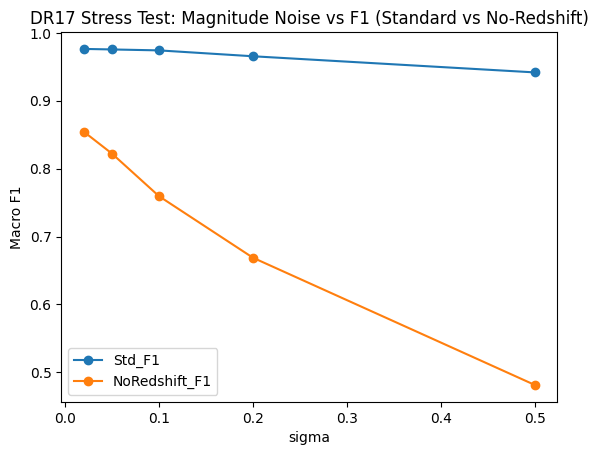

,k,RF macro_F1,kNN macro_F1
0,0,0.982792,0.947038
1,10,0.981302,0.853792
2,50,0.982057,0.742741
3,200,0.977698,0.631201


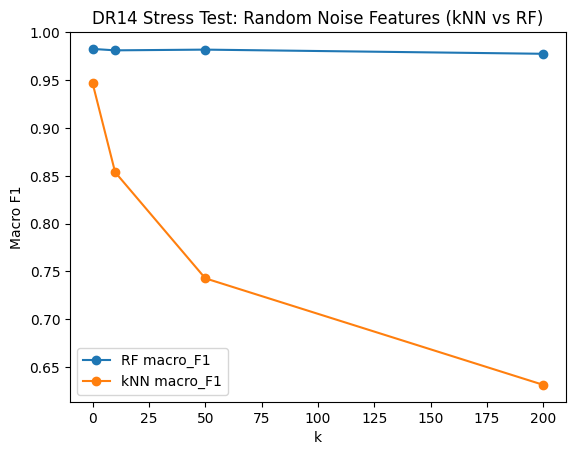

In [ ]:
from sklearn.base import clone

# 1. Gaussian Noise (DR17)
def stress_noise():
    rng = np.random.default_rng(SEED)
    X_test_clean = results['DR17']['X_te'].copy()
    y_test_clean = results['DR17']['y_te']

    best_rf_params = {k.replace('rf__', ''): v for k, v in results['DR17']['search'].best_params_.items()}
    rf_model = RandomForestClassifier(random_state=SEED, n_jobs=-1, **best_rf_params)

    model_standard = Pipeline([('fe', FunctionTransformer(add_features)), ('rf', clone(rf_model))])
    model_standard.fit(results['DR17']['X_tr'], results['DR17']['y_tr'])

    model_noredshift = Pipeline([('fe', FunctionTransformer(add_features, kw_args={'use_redshift': False})), ('rf', clone(rf_model))])
    model_noredshift.fit(results['DR17']['X_tr'], results['DR17']['y_tr'])

    noise_results = []
    for sigma in [0.02, 0.05, 0.1, 0.2, 0.5]:
        X_noisy = X_test_clean.copy()
        for band in ['u', 'g', 'r', 'i', 'z']:
            X_noisy[band] += rng.normal(0, sigma, size=len(X_noisy))

        rep_std = report(y_test_clean, model_standard.predict(X_noisy))
        rep_nr  = report(y_test_clean, model_noredshift.predict(X_noisy))

        noise_results.append({
            'sigma': sigma,
            'Std_F1': rep_std['macro_F1'], 'Std_QSO_Rec': rep_std['recall_QSO'],
            'NoRedshift_F1': rep_nr['macro_F1'], 'NoRedshift_QSO_Rec': rep_nr['recall_QSO']
        })
    return pd.DataFrame(noise_results), rng.bit_generator.state

with timed('Step 11 gaussian noise'):
    df_noise, rng_state = cached('stress_noise.joblib', stress_noise, 'stress')
display(df_noise)
df_noise.plot(x='sigma', y=['Std_F1', 'NoRedshift_F1'], marker='o')
plt.title('DR17 Stress Test: Magnitude Noise vs F1 (Standard vs No-Redshift)')
plt.ylabel('Macro F1')
save_fig('11_stress_gaussian_noise'); plt.show()
save_tab(df_noise, '11_stress_gaussian_noise')

# 2. Random Noise Features (DR14)
def stress_noisecols(state):
    rng = np.random.default_rng(SEED); rng.bit_generator.state = state
    noise_dim_results = []
    for k in [0, 10, 50, 200]:
        X_tr = results['DR14']['X_tr'].copy()
        X_te = results['DR14']['X_te'].copy()
        y_tr = results['DR14']['y_tr']
        y_te = results['DR14']['y_te']

        for i in range(k):
            noise_col = rng.normal(0, 1, size=len(X_tr))
            noise_col_te = rng.normal(0, 1, size=len(X_te))
            X_tr.insert(len(X_tr.columns), f'noise_{i}', noise_col)
            X_te.insert(len(X_te.columns), f'noise_{i}', noise_col_te)

        rf = Pipeline([('fe', FunctionTransformer(add_features)), ('rf', RandomForestClassifier(random_state=SEED, n_jobs=-1))])
        knn = Pipeline([('fe', FunctionTransformer(add_features)), ('sc', StandardScaler()), ('knn', KNeighborsClassifier(n_neighbors=5))])

        rf.fit(X_tr, y_tr)
        knn.fit(X_tr, y_tr)

        rf_f1 = f1_score(y_te, rf.predict(X_te), average='macro')
        knn_f1 = f1_score(y_te, knn.predict(X_te), average='macro')
        noise_dim_results.append({'k': k, 'RF macro_F1': rf_f1, 'kNN macro_F1': knn_f1})
    return pd.DataFrame(noise_dim_results)

with timed('Step 11 noise columns'):
    df_dim = cached('stress_noisecols.joblib', lambda: stress_noisecols(rng_state), 'stress')
display(df_dim)
df_dim.plot(x='k', marker='o')
plt.title('DR14 Stress Test: Random Noise Features (kNN vs RF)')
plt.ylabel('Macro F1')
save_fig('11_stress_noise_features'); plt.show()
save_tab(df_dim, '11_stress_noise_features')


## Step 12: Summary

In [ ]:
import os
summary = []

# Hardcoded paper numbers from phase 1 tables
paper_acc = {'DR14': 0.9885, 'DR16': 0.9901, 'DR17': 0.9808}
paper_bal_acc = {'DR14': 0.9866, 'DR16': 0.9861, 'DR17': 0.9815}
paper_macro_recall = {'DR14': 0.9792, 'DR16': 0.9783, 'DR17': 0.9756}

for name in ['DR14', 'DR16', 'DR17']:
    res = results[name]
    def_rep = report(res['y_te'], res['default'].predict(res['X_te']))
    tun_rep = report(res['y_te'], res['search'].predict(res['X_te']))
    
    # Attempt to load Nested CV stats
    nested_str = "Run Step 8"
    if os.path.exists(f'nested_{name}.csv'):
        ndf = pd.read_csv(f'nested_{name}.csv')
        nested_str = f"{ndf['test_f1_macro'].mean():.4f} ± {ndf['test_f1_macro'].std():.4f}"
    
    summary.append({
        'Dataset': name,
        'Model': 'Paper RF (accuracy recomputed from CMs)',
        'Accuracy': paper_acc[name],
        'Paper-style BA': paper_bal_acc[name],
        'Macro Recall': paper_macro_recall[name],
        'Macro F1': np.nan,
        'Nested CV Macro F1': np.nan
    })
    summary.append({
        'Dataset': name,
        'Model': 'Fixed Baseline (Default RF, 8 + colours)',
        'Accuracy': def_rep['accuracy'],
        'Paper-style BA': def_rep['paper_style_BA'],
        'Macro Recall': def_rep['balanced_acc (macro-recall)'],
        'Macro F1': def_rep['macro_F1'],
        'Nested CV Macro F1': np.nan
    })
    summary.append({
        'Dataset': name,
        'Model': 'Fixed Tuned RF',
        'Accuracy': tun_rep['accuracy'],
        'Paper-style BA': tun_rep['paper_style_BA'],
        'Macro Recall': tun_rep['balanced_acc (macro-recall)'],
        'Macro F1': tun_rep['macro_F1'],
        'Nested CV Macro F1': nested_str,
        # --- Phase 2 extensions (Steps 6b, 6c, 10b) ---
        'log_loss': prob_tables[name].loc['log_loss', 'tuned RF'],
        'AP_QSO': prob_tables[name].loc['AP_QSO', 'tuned RF'],
        'ROC_AUC_macro_ovr': prob_tables[name].loc['ROC_AUC_macro_ovr', 'tuned RF'],
        'train_test_F1_gap': gap_df.query("Dataset == @name and Model == 'tuned RF'")['gap'].iloc[0],
        'fit_s (DR17 only)': eff.loc['Tuned RF', 'fit_s'] if name == 'DR17' else np.nan,
        'model_size_MB (DR17 only)': eff.loc['Tuned RF', 'model_size_MB'] if name == 'DR17' else np.nan
    })

    # Tuned HistGB
    hs = res['hgb']
    gb_rep = report(res['y_te'], hs.predict(res['X_te']))
    gb_prob, *_ = prob_report(hs.best_estimator_, res['X_te'], res['y_te'])
    gb_gap = (f1_score(res['y_tr'], hs.predict(res['X_tr']), average='macro')
              - f1_score(res['y_te'], hs.predict(res['X_te']), average='macro'))
    summary.append({
        'Dataset': name,
        'Model': 'Tuned HistGB',
        'Accuracy': gb_rep['accuracy'],
        'Paper-style BA': gb_rep['paper_style_BA'],
        'Macro Recall': gb_rep['balanced_acc (macro-recall)'],
        'Macro F1': gb_rep['macro_F1'],
        'Nested CV Macro F1': np.nan,
        'log_loss': gb_prob['log_loss'],
        'AP_QSO': gb_prob['AP_QSO'],
        'ROC_AUC_macro_ovr': gb_prob['ROC_AUC_macro_ovr'],
        'train_test_F1_gap': gb_gap,
        'fit_s (DR17 only)': eff.loc['Tuned HistGB', 'fit_s'] if name == 'DR17' else np.nan,
        'model_size_MB (DR17 only)': eff.loc['Tuned HistGB', 'model_size_MB'] if name == 'DR17' else np.nan
    })

df_sum = pd.DataFrame(summary)
display(df_sum)
df_sum.to_csv(TAB / '12_summary.csv', index=False)


,Dataset,Model,Accuracy,Paper-style BA,Macro Recall,Macro F1,Nested CV Macro F1,log_loss,AP_QSO,ROC_AUC_macro_ovr,train_test_F1_gap,fit_s (DR17 only),model_size_MB (DR17 only)
0,DR14,Paper RF (accuracy recomputed from CMs),0.98850,0.986600,0.979200,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,DR14,"Fixed Baseline (Default RF, 8 + colours)",0.98950,0.986894,0.979844,0.982792,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,DR14,Fixed Tuned RF,0.99200,0.990115,0.984765,0.986268,0.9852 ± 0.0013,0.043574,0.992232,0.998870,0.004689,NaN,NaN
3,DR14,Tuned HistGB,0.98850,0.985335,0.977550,0.982756,NaN,0.042122,0.991792,0.998656,0.016579,NaN,NaN
4,DR16,Paper RF (accuracy recomputed from CMs),0.99010,0.986100,0.978300,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,DR16,"Fixed Baseline (Default RF, 8 + colours)",0.99375,0.991047,0.985846,0.988824,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,DR16,Fixed Tuned RF,0.99425,0.991574,0.986580,0.989328,0.9887 ± 0.0013,0.026696,0.991796,0.999027,0.003761,NaN,NaN
7,DR16,Tuned HistGB,0.99095,0.989433,0.984201,0.986208,NaN,0.026330,0.992411,0.999003,0.005607,NaN,NaN
8,DR17,Paper RF (accuracy recomputed from CMs),0.98080,0.981500,0.975600,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,DR17,"Fixed Baseline (Default RF, 8 + colours)",0.97890,0.978909,0.972047,0.975440,NaN,NaN,NaN,NaN,NaN,NaN,NaN
